# Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/tech-layoffs-2020-2024/tech_layoffs.xlsx


# Exploring the Dataset: Understanding the Data at Hand

In [2]:
dataset = pd.read_excel("/kaggle/input/tech-layoffs-2020-2024/tech_layoffs.xlsx")
dataset.head()

,#,Company,Location_HQ,Country,Continent,Laid_Off,Date_layoffs,Percentage,Company_Size_before_Layoffs,Company_Size_after_layoffs,Industry,Stage,Money_Raised_in_$_mil,Year,lat,lng
0,3,ShareChat,Bengaluru,India,Asia,200,2023-12-20,15.0,1333,1133,Consumer,Series H,$1700,2023,12.97194,77.59369
1,4,InSightec,Haifa,Israel,Asia,100,2023-12-19,20.0,500,400,Healthcare,Unknown,$733,2023,32.81841,34.98850
2,6,Enphase Energy,San Francisco Bay Area,USA,North America,350,2023-12-18,10.0,3500,3150,Energy,Post-IPO,$116,2023,37.54827,-121.98857
3,7,Udaan,Bengaluru,India,Asia,100,2023-12-18,10.0,1000,900,Retail,Unknown,1500,2023,12.97194,77.59369
4,14,Cruise,San Francisco Bay Area,USA,North America,900,2023-12-14,24.0,3750,2850,Transportation,Acquired,$15000,2023,37.77493,-122.41942


In [3]:
dataset.columns

Index(['#', 'Company', 'Location_HQ', 'Country', 'Continent', 'Laid_Off',
       'Date_layoffs', 'Percentage', 'Company_Size_before_Layoffs',
       'Company_Size_after_layoffs', 'Industry', 'Stage',
       'Money_Raised_in_$_mil', 'Year', 'lat', 'lng'],
      dtype='object')

In [4]:
# Drop unnecessary Column 
dataset.drop(dataset.columns[0], axis=1, inplace=True)
dataset.head()

,Company,Location_HQ,Country,Continent,Laid_Off,Date_layoffs,Percentage,Company_Size_before_Layoffs,Company_Size_after_layoffs,Industry,Stage,Money_Raised_in_$_mil,Year,lat,lng
0,ShareChat,Bengaluru,India,Asia,200,2023-12-20,15.0,1333,1133,Consumer,Series H,$1700,2023,12.97194,77.59369
1,InSightec,Haifa,Israel,Asia,100,2023-12-19,20.0,500,400,Healthcare,Unknown,$733,2023,32.81841,34.98850
2,Enphase Energy,San Francisco Bay Area,USA,North America,350,2023-12-18,10.0,3500,3150,Energy,Post-IPO,$116,2023,37.54827,-121.98857
3,Udaan,Bengaluru,India,Asia,100,2023-12-18,10.0,1000,900,Retail,Unknown,1500,2023,12.97194,77.59369
4,Cruise,San Francisco Bay Area,USA,North America,900,2023-12-14,24.0,3750,2850,Transportation,Acquired,$15000,2023,37.77493,-122.41942


In [5]:
dataset['Country'].unique()

array(['India', 'Israel', 'USA', 'Sweden', 'United Kingdom', 'Canada',
       'France', 'Netherlands', 'Germany', 'Estonia', 'Kenya', 'Brazil',
       'New Zealand', 'Ireland', 'Australia', 'Singapore', 'Chile',
       'Spain', 'South Korea', 'Indonesia', 'Japan', 'China', 'Argentina',
       'Nigeria', 'United Arabian Emirates', 'Denmark', 'Norway',
       'Thailand', 'Senegal', 'Hong Kong', 'Austria', 'Finland',
       'Malaysia', 'Mexico', 'Russia', 'Switzerland', 'Portugal'],
      dtype=object)

In [6]:
dataset.dtypes

Company                                object
Location_HQ                            object
Country                                object
Continent                              object
Laid_Off                                int64
Date_layoffs                   datetime64[ns]
Percentage                            float64
Company_Size_before_Layoffs             int64
Company_Size_after_layoffs              int64
Industry                               object
Stage                                  object
Money_Raised_in_$_mil                  object
Year                                    int64
lat                                   float64
lng                                   float64
dtype: object

# EDA by Country

In [7]:
top_countries = dataset.groupby('Country')['Laid_Off'].sum().nlargest(5)

# Convert the result back to a DataFrame for visualization
top_countries_df = top_countries.reset_index()

# Create an interactive bar plot using Plotly
fig = px.bar(top_countries_df, x='Country', y='Laid_Off', title='Top 5 Countries with Highest Layoffs')
fig.show()

#### Let's examine these top 5 countries

In [8]:
grouped_data = dataset.groupby('Country').apply(lambda x: x.reset_index(drop=True))

/tmp/ipykernel_18/4228103421.py:1: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



In [9]:
usa_data = grouped_data.loc['USA']
india_data = grouped_data.loc['India']
germany_data = grouped_data.loc['Germany']
sweden_data = grouped_data.loc['Sweden']
uk_data = grouped_data.loc['United Kingdom']

In [10]:
def total_layoffs_over_years(df):
    return df.groupby('Year')['Laid_Off'].sum()

def average_layoffs_per_year(df):
    return df.groupby('Year')['Laid_Off'].mean()

def percentage_change_in_layoffs(df):
    return df.groupby('Year')['Laid_Off'].pct_change() * 100

def largest_layoffs_events(df, n=5, by='percentage'):
    if by == 'percentage':
        return df.nlargest(n, 'Percentage')
    elif by == 'absolute':
        return df.nlargest(n, 'Laid_Off')

def layoffs_by_industry(df):
    return df.groupby('Industry')['Laid_Off'].sum()

In [11]:
for country, country_data in [('USA', usa_data), ('India', india_data), ('Germany', germany_data), ('Sweden', sweden_data), ('United Kingdom', uk_data)]:
    print(f"Insights for {country}:")
    print("Total layoffs over the years:")
    print(total_layoffs_over_years(country_data))
    print("\nAverage layoffs per year:")
    print(average_layoffs_per_year(country_data))
    print("\nPercentage change in layoffs over the years:")
    print(percentage_change_in_layoffs(country_data))
    print("\nTop 5 largest layoffs events:")
    print(largest_layoffs_events(country_data))
    print("\nLayoffs by industry:")
    print(layoffs_by_industry(country_data))
    print("\n\n")

Insights for USA:
Total layoffs over the years:
Year
2020     44217
2021      6137
2022     92755
2023    126822
2024      4050
Name: Laid_Off, dtype: int64

Average layoffs per year:
Year
2020    185.785714
2021    681.888889
2022    270.422741
2023    418.554455
2024    337.500000
Name: Laid_Off, dtype: float64

Percentage change in layoffs over the years:
0               NaN
1        157.142857
2        -85.555556
3         80.769231
4         -4.255319
           ...     
900      -41.269841
901      -72.972973
902    17900.000000
903      -97.222222
904      300.000000
Name: Laid_Off, Length: 905, dtype: float64

Top 5 largest layoffs events:
          Company    Location_HQ Country      Continent  Laid_Off  \
6          Zulily        Seattle     USA  North America       839   
20         Convoy        Seattle     USA  North America       500   
93        Bitwise         Fresno     USA  North America       900   
396  Fifth Season     Pittsburgh     USA  North America       100   

# Layoffs Insights Report:

### USA:

**Total Layoffs Over the Years:**
- The number of layoffs in the USA has fluctuated significantly over the years, peaking in 2023 with 126,822 layoffs. This suggests potential instability in the job market during that period.

**Average Layoffs per Year:**
- The average number of layoffs per year shows a varied trend, indicating volatility in employment stability over time.

**Percentage Change in Layoffs Over the Years:**
- There have been substantial fluctuations in the percentage change of layoffs from year to year, indicating periods of significant shifts in the job market.

**Top 5 Largest Layoffs Events:**
1. Zulily - 839 layoffs
2. Convoy - 500 layoffs
3. Bitwise - 900 layoffs
4. Fifth Season - 100 layoffs
5. Playdots - 65 layoffs

**Layoffs by Industry:**
- The most affected industries include Consumer, Retail, Finance, Transportation, and Real Estate. Understanding layoffs by industry can help identify sectors facing the most challenges.

### India:

**Total Layoffs Over the Years:**
- India experienced a noticeable increase in layoffs from 2020 to 2022, followed by a decrease in 2023. The low number of layoffs in 2021 suggests relative stability compared to other years.

**Average Layoffs per Year:**
- The average number of layoffs per year shows fluctuations, indicating varying degrees of employment stability.

**Percentage Change in Layoffs Over the Years:**
- Percentage changes in layoffs indicate periods of both growth and decline in job market stability, with particularly sharp changes in some years.

**Top 5 Largest Layoffs Events:**
1. ZestMoney - 150 layoffs
2. FrontRow - 4 layoffs
3. Crejo.Fun - 170 layoffs
4. Udayy - 100 layoffs
5. FrontRow - 39 layoffs

**Layoffs by Industry:**
- The most affected industries include Education, Food, Finance, Transportation, and Marketing. Understanding layoffs by industry helps in identifying sectors requiring attention and support.

### Germany:

**Total Layoffs Over the Years:**
- Germany experienced a notable increase in layoffs in 2023, reaching 12,118, which could indicate economic challenges or restructuring within industries.

**Average Layoffs per Year:**
- The average number of layoffs per year shows fluctuations, with a significant increase observed in 2023, possibly indicating a period of economic uncertainty.

**Percentage Change in Layoffs Over the Years:**
- Percentage changes in layoffs exhibit substantial fluctuations, suggesting volatile shifts in the job market over time.

**Top 5 Largest Layoffs Events:**
1. Dropp - 60 layoffs
2. Planetly - 200 layoffs
3. Zeitgold - 75 layoffs
4. Pitch - 80 layoffs
5. Infarm - 500 layoffs

**Layoffs by Industry:**
- Industries such as Finance, Food, Healthcare, Media, and Transportation are among the most affected, indicating potential areas of concern for employment stability.

### Sweden:

**Total Layoffs Over the Years:**
- Sweden experienced a significant increase in layoffs from 2022 to 2023, suggesting potential economic challenges or industry-specific issues.

**Average Layoffs per Year:**
- The average number of layoffs per year shows a substantial increase in 2023, indicating a period of economic instability.

**Percentage Change in Layoffs Over the Years:**
- Percentage changes in layoffs exhibit notable fluctuations, suggesting varying degrees of job market stability over time.

**Top 5 Largest Layoffs Events:**
1. Juni - 72 layoffs
2. Oda - 70 layoffs
3. Spotify - 1500 layoffs
4. Acast - 70 layoffs
5. Voi - 130 layoffs

**Layoffs by Industry:**
- Finance, Food, Healthcare, Media, and Transportation are among the most affected industries, highlighting areas that may require targeted interventions or support.

### United Kingdom:

**Total Layoffs Over the Years:**
- The United Kingdom saw fluctuations in layoffs over the years, with notable peaks in 2020 and 2023, indicating potential economic challenges or industry-specific issues.

**Average Layoffs per Year:**
- Average layoffs per year show variations, with a notable increase observed in 2023, suggesting potential economic instability.

**Percentage Change in Layoffs Over the Years:**
- Percentage changes in layoffs exhibit significant fluctuations, indicating varying levels of job market stability over time.

**Top 5 Largest Layoffs Events:**
1. Glisser - 25 layoffs
2. Britishvolt - 206 layoffs
3. OneWeb - 451 layoffs
4. Docly - 8 layoffs
5. Arrival - 800 layoffs

**Layoffs by Industry:**
- Aerospace, Crypto, Finance, Food, Healthcare, Marketing, Media, and Transportation are among the most affected industries, indicating areas requiring attention and support.

# EDA by Year

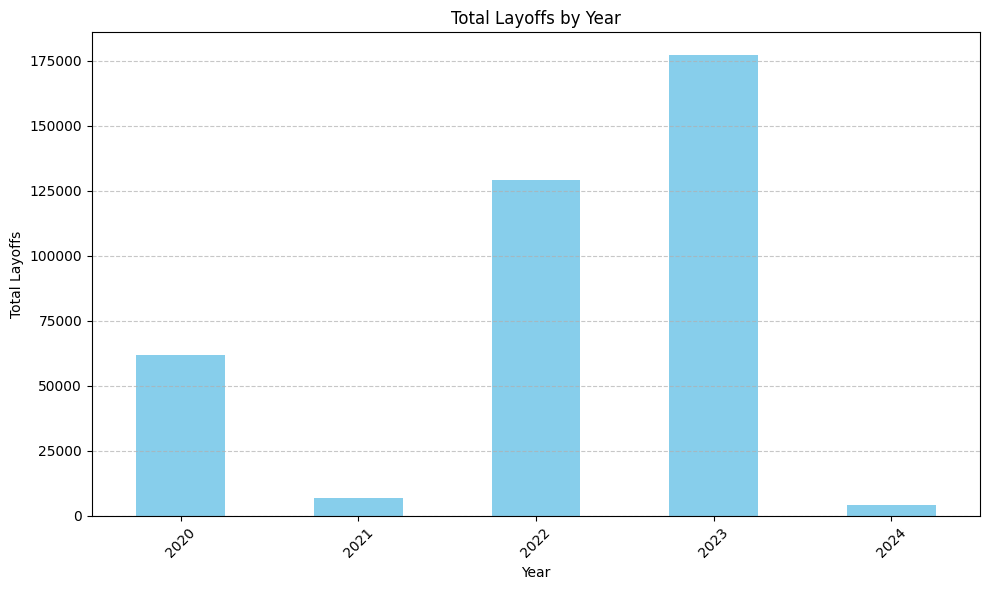

In [12]:
# Group the dataset by year and sum up the layoffs for each year
yearly_layoffs = dataset.groupby('Year')['Laid_Off'].sum()

# Plotting
plt.figure(figsize=(10, 6))
yearly_layoffs.plot(kind='bar', color='skyblue')
plt.title('Total Layoffs by Year')
plt.xlabel('Year')
plt.ylabel('Total Layoffs')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [13]:
def plot_layoffs_by_industry(dataset, year):
    # Filter the dataset for the specified year
    layoffs_year = dataset[dataset['Year'] == year]
    
    # Group the filtered dataset by industry and sum up the layoffs for each industry
    layoffs_by_industry = layoffs_year.groupby('Industry')['Laid_Off'].sum()
    
    # Plotting
    plt.figure(figsize=(12, 8))
    layoffs_by_industry.sort_values(ascending=False).plot(kind='bar', color='salmon')
    plt.title(f'Layoffs by Industry in {year}')
    plt.xlabel('Industry')
    plt.ylabel('Total Layoffs')
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

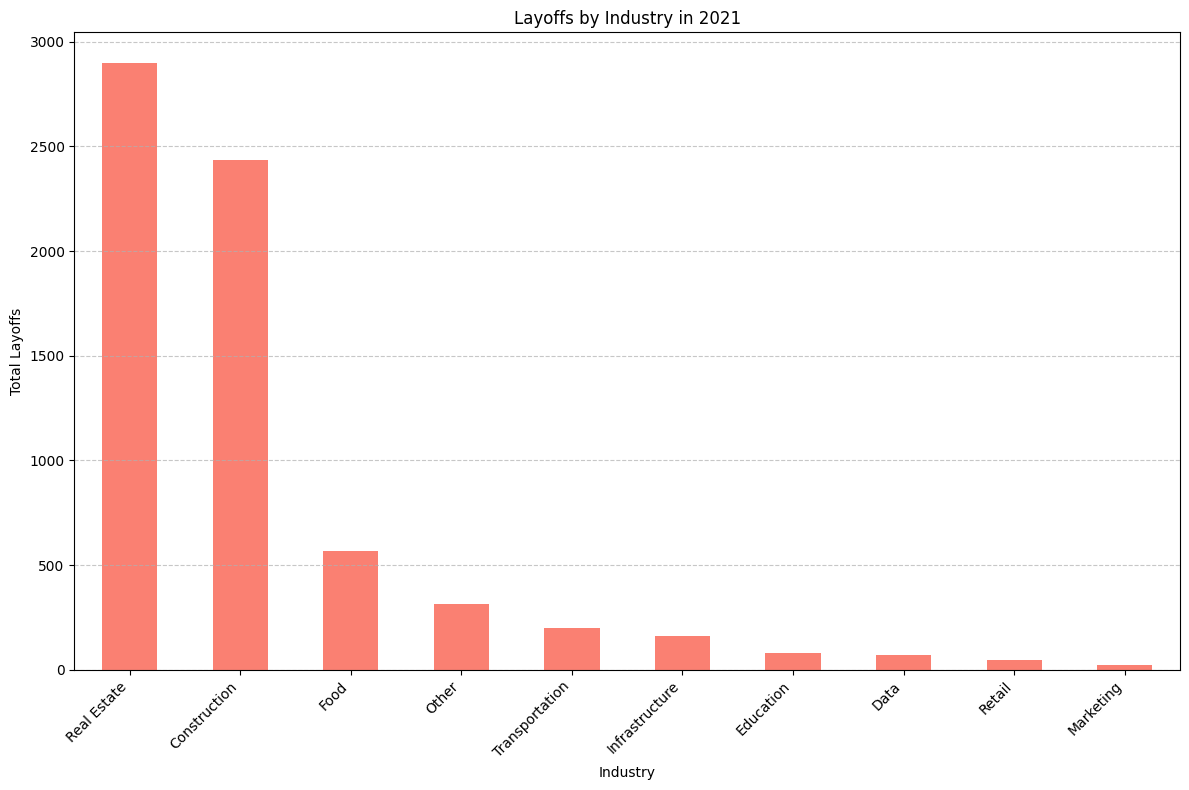

In [14]:
plot_layoffs_by_industry(dataset, 2021)

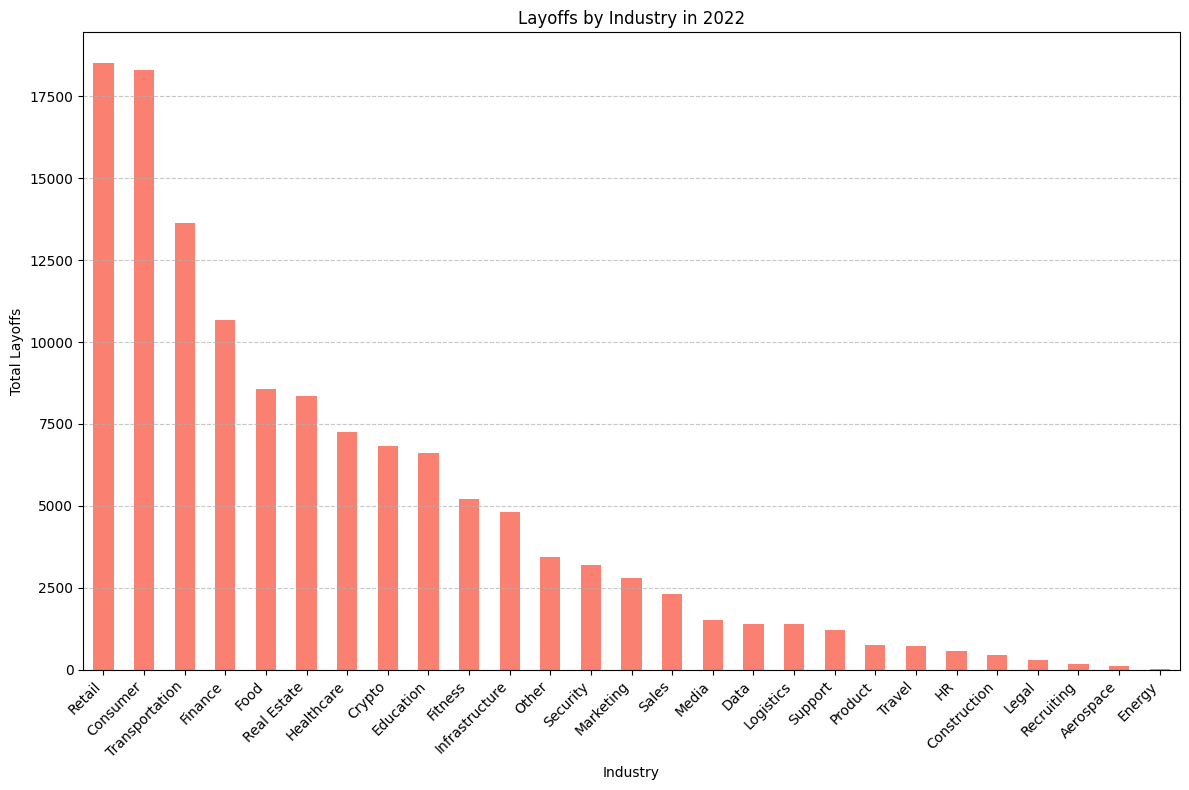

In [15]:
plot_layoffs_by_industry(dataset, 2022)

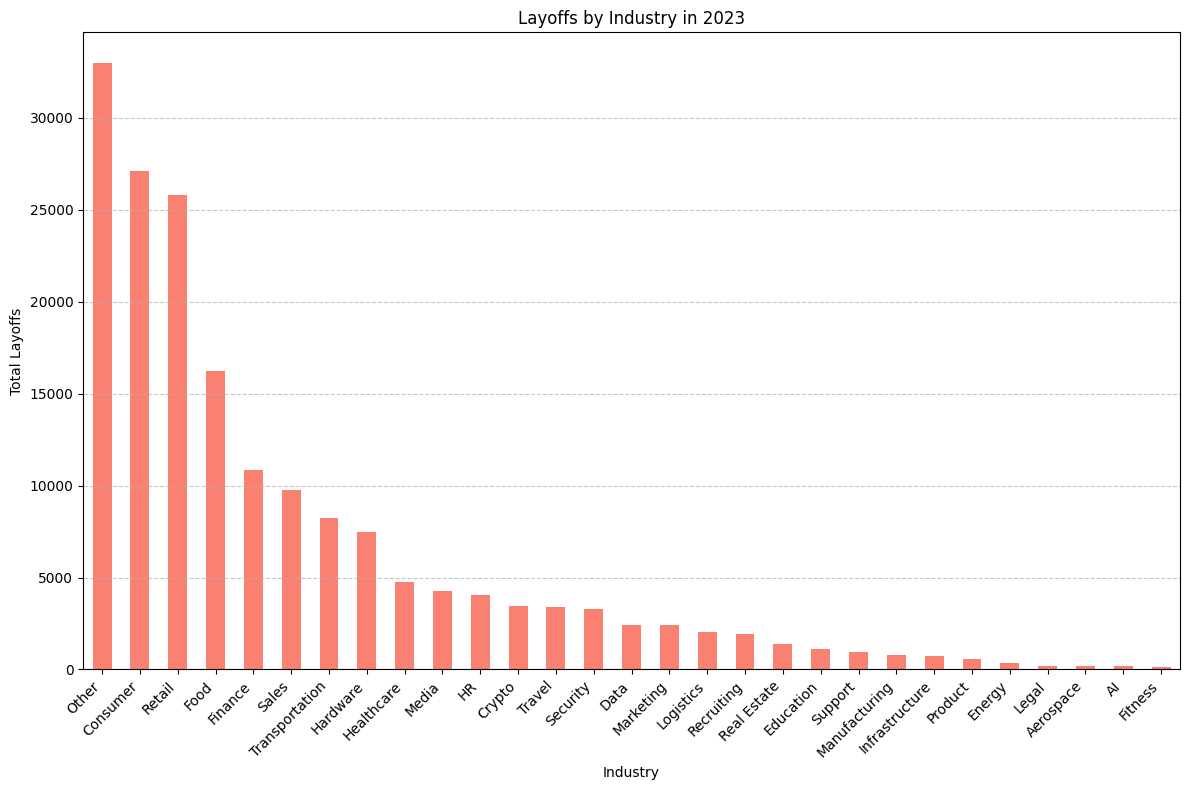

In [16]:
plot_layoffs_by_industry(dataset, 2023)

# EDA by Company

In [17]:
# Calculate the percentage change in company size before and after layoffs
dataset['Size_Change_Percentage'] = ((dataset['Company_Size_after_layoffs'] - dataset['Company_Size_before_Layoffs']) / dataset['Company_Size_before_Layoffs']) * 100

# Display the first few rows to verify the new column
dataset.head()

,Company,Location_HQ,Country,Continent,Laid_Off,Date_layoffs,Percentage,Company_Size_before_Layoffs,Company_Size_after_layoffs,Industry,Stage,Money_Raised_in_$_mil,Year,lat,lng,Size_Change_Percentage
0,ShareChat,Bengaluru,India,Asia,200,2023-12-20,15.0,1333,1133,Consumer,Series H,$1700,2023,12.97194,77.59369,-15.003751
1,InSightec,Haifa,Israel,Asia,100,2023-12-19,20.0,500,400,Healthcare,Unknown,$733,2023,32.81841,34.98850,-20.000000
2,Enphase Energy,San Francisco Bay Area,USA,North America,350,2023-12-18,10.0,3500,3150,Energy,Post-IPO,$116,2023,37.54827,-121.98857,-10.000000
3,Udaan,Bengaluru,India,Asia,100,2023-12-18,10.0,1000,900,Retail,Unknown,1500,2023,12.97194,77.59369,-10.000000
4,Cruise,San Francisco Bay Area,USA,North America,900,2023-12-14,24.0,3750,2850,Transportation,Acquired,$15000,2023,37.77493,-122.41942,-24.000000


In [18]:
# Check for duplicates in 'Company'
duplicates = dataset['Company'].duplicated()

# Print the rows with duplicates
print(dataset[duplicates])

           Company             Location_HQ  Country      Continent  Laid_Off  \
72    Kenko Health                  Mumbai    India           Asia        50   
98           Paper                Montreal   Canada  North America       106   
136         Convoy                 Seattle      USA  North America        30   
144       FrontRow               Bengaluru    India           Asia        39   
155        23andMe  San Francisco Bay Area      USA  North America        75   
...            ...                     ...      ...            ...       ...   
1405       Sisense           New York City      USA  North America        60   
1406        Google  San Francisco Bay Area      USA  North America      1000   
1412         Unity  San Francisco Bay Area      USA  North America      1800   
1413         Pitch                  Berlin  Germany         Europe        80   
1417     Frontdesk               Milwaukee      USA  North America       200   

     Date_layoffs  Percentage  Company_

##### Given the presence of duplicates in the 'Company' column, it indicates that certain companies have conducted multiple rounds of layoffs over the years. To gain further insight, let's explore the top companies based on the frequency of their appearances in the dataset.

In [19]:
# Count the occurrences of each company name
company_counts = dataset['Company'].value_counts()

# Get the top 5 companies
top_5_companies = company_counts.head(5)

# Display the top 5 companies
print("Top 5 Companies with Most Layoffs:")
print(top_5_companies)

Top 5 Companies with Most Layoffs:
Company
Uber      5
Blend     5
Gopuff    5
Swiggy    5
Unity     5
Name: count, dtype: int64


In [20]:
company_data = dataset.groupby('Company').apply(lambda x: x.reset_index(drop=True))

/tmp/ipykernel_18/1328510622.py:1: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



In [21]:
uber_data = company_data.loc['Uber']
blend_data = company_data.loc['Blend']
gopuff_data = company_data.loc['Gopuff']
swiggy_data = company_data.loc['Swiggy']
unity_data = company_data.loc['Unity']

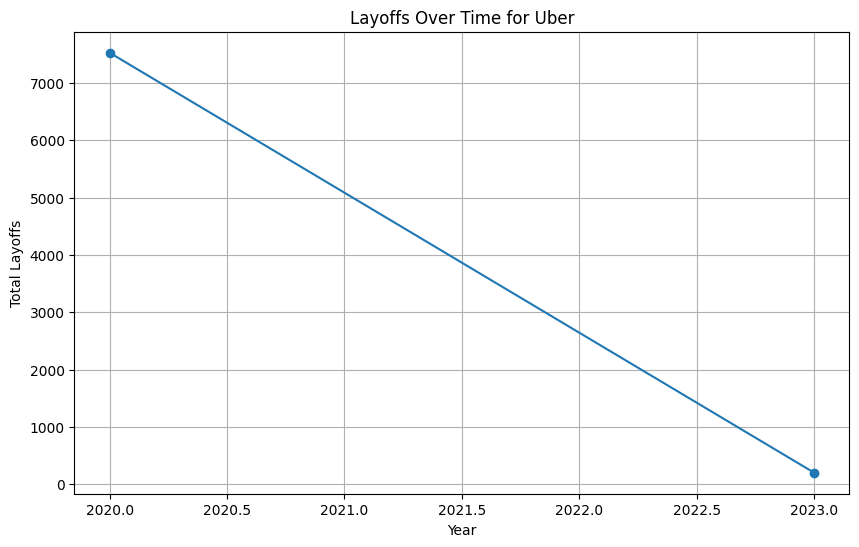

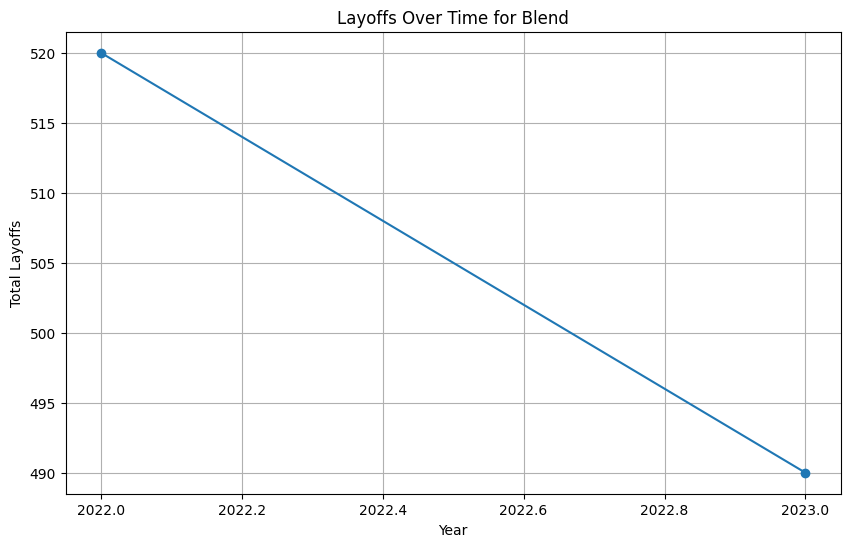

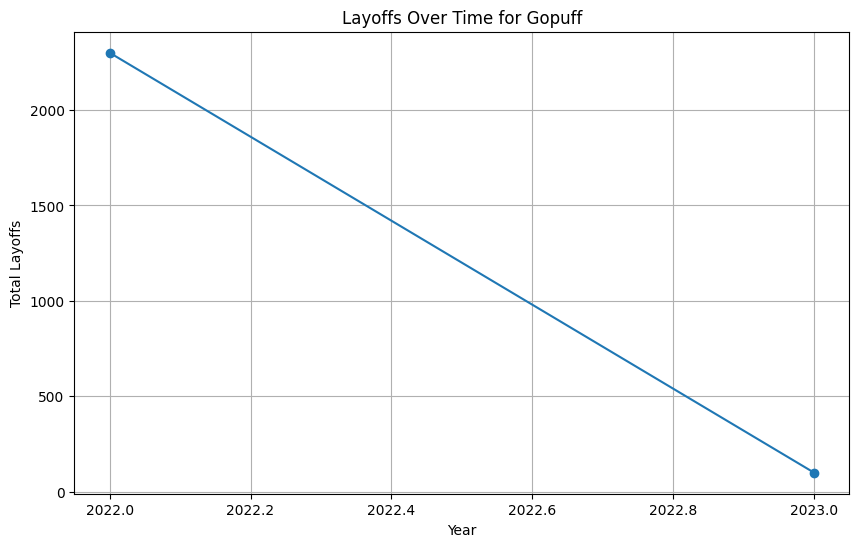

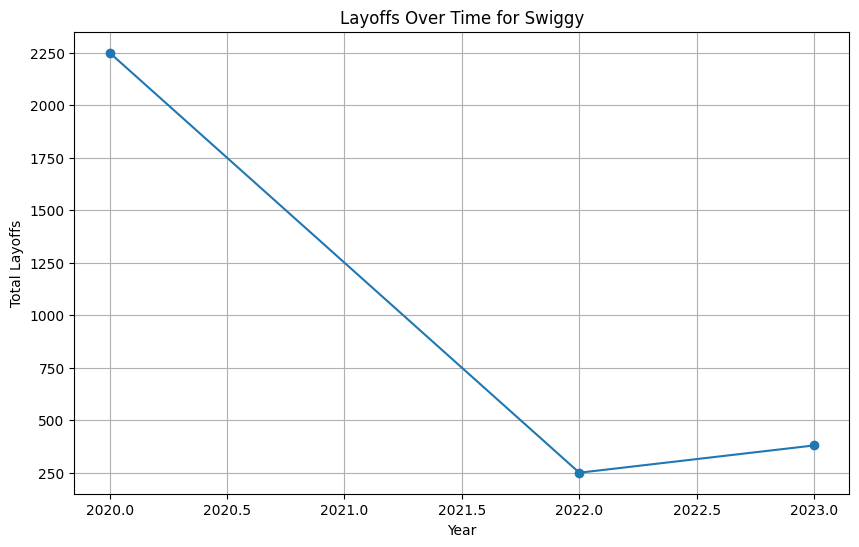

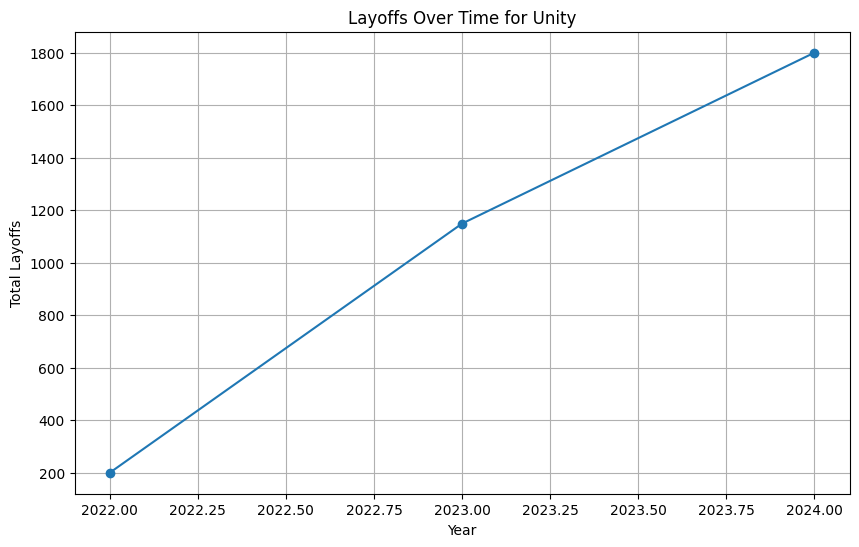

In [22]:
def plot_layoffs_over_time(company_data, company_name):
    plt.figure(figsize=(10, 6))
    company_data.groupby('Year')['Laid_Off'].sum().plot(marker='o')
    plt.title(f'Layoffs Over Time for {company_name}')
    plt.xlabel('Year')
    plt.ylabel('Total Layoffs')
    plt.grid(True)
    plt.show()

plot_layoffs_over_time(uber_data, 'Uber')
plot_layoffs_over_time(blend_data, 'Blend')
plot_layoffs_over_time(gopuff_data, 'Gopuff')
plot_layoffs_over_time(swiggy_data, 'Swiggy')
plot_layoffs_over_time(unity_data, 'Unity')

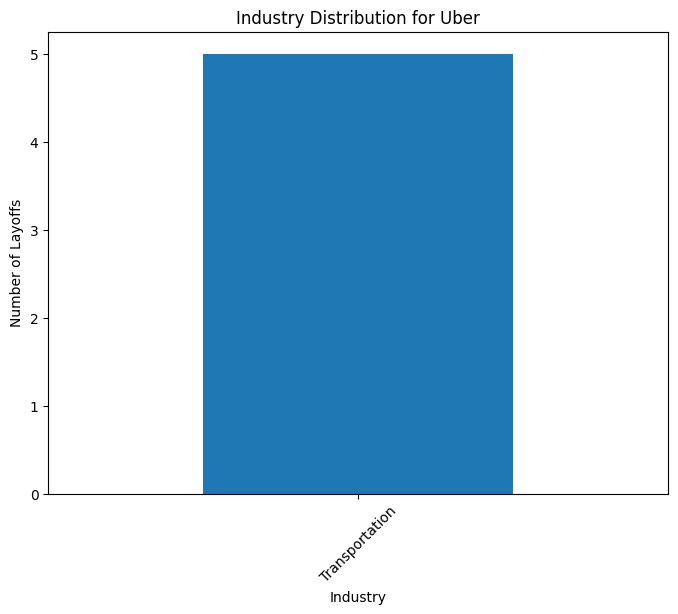

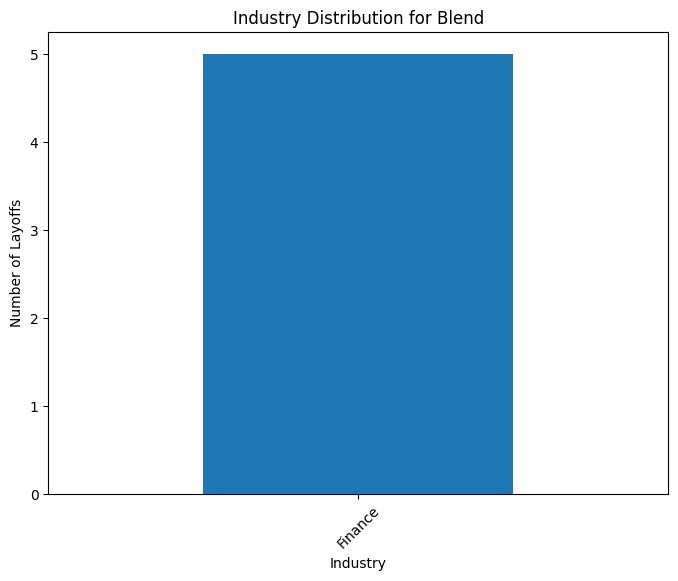

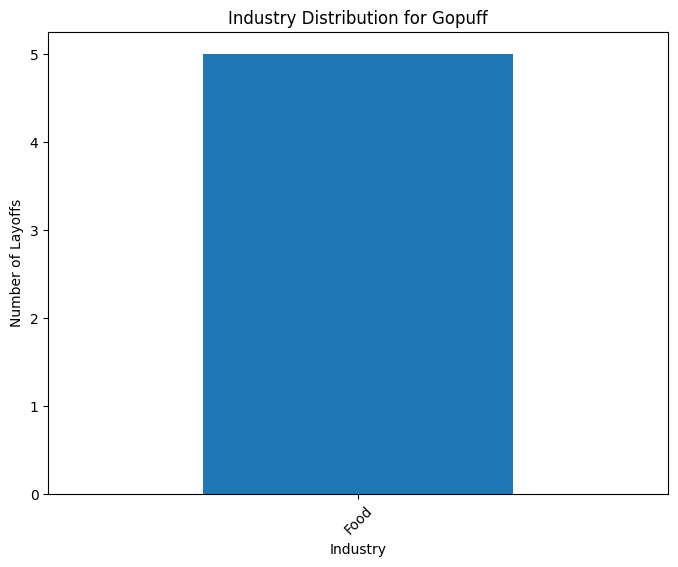

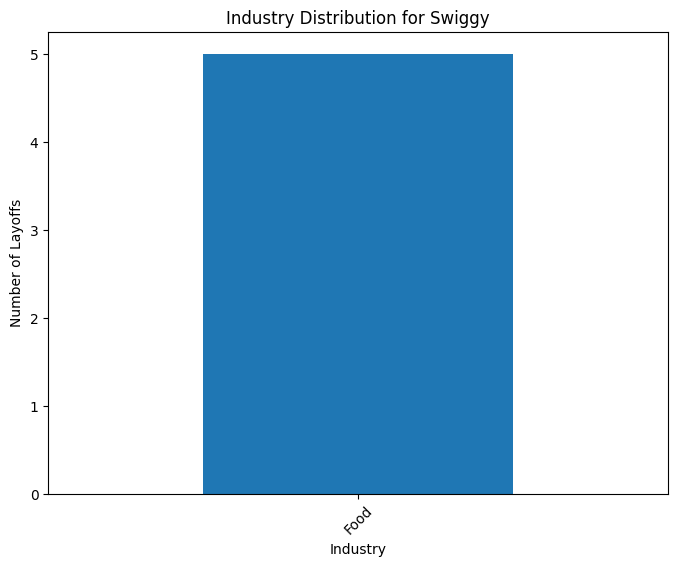

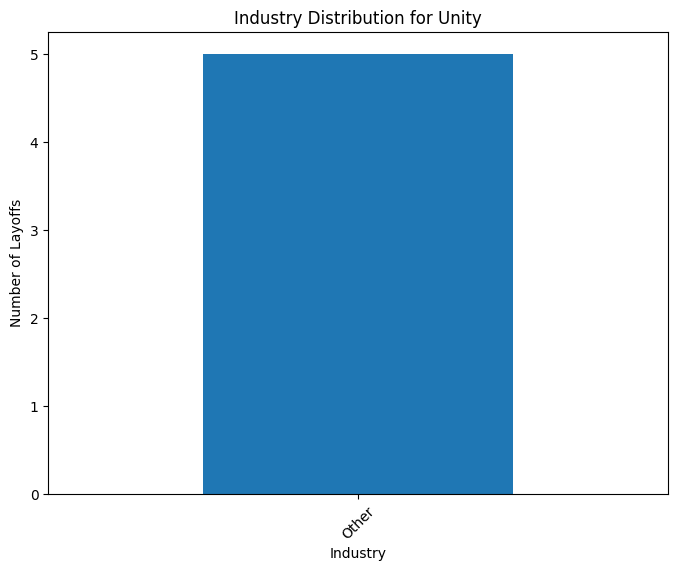

In [23]:
def industry_analysis(company_data, company_name):
    industry_counts = company_data['Industry'].value_counts()
    plt.figure(figsize=(8, 6))
    industry_counts.plot(kind='bar')
    plt.title(f'Industry Distribution for {company_name}')
    plt.xlabel('Industry')
    plt.ylabel('Number of Layoffs')
    plt.xticks(rotation=45)
    plt.show()

industry_analysis(uber_data, 'Uber')
industry_analysis(blend_data, 'Blend')
industry_analysis(gopuff_data, 'Gopuff')
industry_analysis(swiggy_data, 'Swiggy')
industry_analysis(unity_data, 'Unity')

In [24]:
def size_change_analysis(company_data, company_name):
    avg_size_change = (company_data['Company_Size_after_layoffs'] - company_data['Company_Size_before_Layoffs']).mean()
    print(f'Average Size Change after Layoffs for {company_name}: {avg_size_change:.2f}%')

size_change_analysis(uber_data, 'Uber')
size_change_analysis(blend_data, 'Blend')
size_change_analysis(gopuff_data, 'Gopuff')
size_change_analysis(swiggy_data, 'Swiggy')
size_change_analysis(unity_data, 'Unity')

Average Size Change after Layoffs for Uber: -1545.00%
Average Size Change after Layoffs for Blend: -202.00%
Average Size Change after Layoffs for Gopuff: -480.00%
Average Size Change after Layoffs for Swiggy: -576.00%
Average Size Change after Layoffs for Unity: -629.80%
